# InfluxDB Benchmarks – Big Experiments

## Libraries

In [1]:
from fabric import ThreadingGroup, Connection
from chi import server, ssh
import os
import warnings
import time
import sys
sys.path.append('../scripts')
from utilities import *
warnings.filterwarnings('ignore')

## Configurations

In [2]:
sshUser = "ubuntu"
server_ips = ["64.131.114.155"]
server_local_ips = {}
client_ips = ["64.131.114.143", "64.131.114.145", "64.131.114.146", "64.131.114.147",
              "64.131.114.148", "64.131.114.152", "64.131.114.153", "64.131.114.154"]

storageType = {"HDD": "/HDD", "NVME": "/NVME_RAID-0"}
SERVER_WORKING_DIR = storageType["NVME"]

## Initialize environment

In [3]:
# These groups are for processing in parallel 
serverConnections = [makeConnection(i, user=sshUser) for i in server_ips]
clientConnections = [makeConnection(i, user=sshUser) for i in client_ips]
allConnections = (serverConnections + clientConnections)
serverGroup = ThreadingGroup.from_connections(serverConnections)
clientGroup = ThreadingGroup.from_connections(clientConnections)
allGroup = ThreadingGroup.from_connections(allConnections)

# Get local IP for server
local_ips = serverGroup.run("hostname -I | cut -d ' ' -f 1", hide=True)
for i in local_ips:
    server_local_ips[i.host] = local_ips[i].stdout.strip()

# Update & Upgrade latest packages
allGroup.run("sudo apt update && sudo apt upgrade -y", hide=True)
rebootGroup(allGroup)

Wait for all server to come online after reboot

In [4]:
# Buffer of reboot (no more +1 min shutdown-schedule delay)
time.sleep(240)

for ip in (server_ips + client_ips):
    waitForSSH(ip, user=sshUser, timeout=1200)

## Datasets

Preparing test datasets on client nodes

In [5]:
clientGroup.put("../scripts/initData.sh")
clientGroup.run("bash initData.sh MYSTIC@IIT", hide=True);

## Benchmark server (InfluxDB)

Prepare benchmark server

In [6]:
serverGroup.put("../scripts/_common.sh")
serverGroup.put("../scripts/InfluxDB/initInfluxDBServer.sh")
serverGroup.run(f"sudo chmod -R 777 {SERVER_WORKING_DIR}; bash initInfluxDBServer.sh {SERVER_WORKING_DIR} true", hide=True);

## Benchmark client (XBench)
Prepare benchmark client

In [7]:
clientGroup.put("../scripts/initXBenchClient.sh")
clientGroup.run("bash initXBenchClient.sh", hide=True)
clientGroup.close()

## Experiments - Settings

In [8]:
targetThreads = [1, 2, 4, 8]
numClients = [i * len(client_ips) for i in targetThreads]

## Experiment – UNARY INSERT (SEQ)
**Perform experiments**

In [9]:
runWorkload("INSERT_UNARY_SEQ", targetThreads, server_local_ips[server_ips[0]], 9492, "InfluxDB", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1760386952
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1760386900 | Delta: 52
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1760387130
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1760387076 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1760387313
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1760387259 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1760387568
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1760387455 | Delta: 113
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1760387462 | Delta: 106
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

**Visualization**

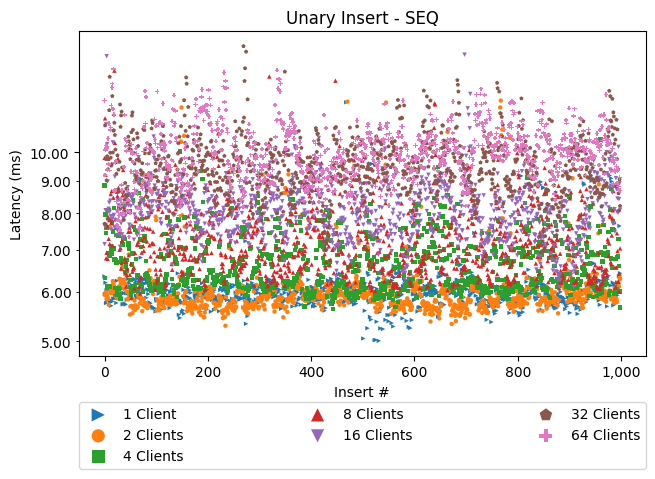

In [10]:
unaryPlots("INSERT_UNARY_SEQ", "InfluxDB", targetThreads, client_ips, "Insert", logScale=True)

## Experiment – UNARY INSERT (RAND)
**Perform experiments**

In [11]:
runWorkload("INSERT_UNARY_RAND", targetThreads, server_local_ips[server_ips[0]], 9492, "InfluxDB", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1760388961
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1760388907 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1760389139
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1760389085 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1760389323
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1760389269 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1760389577
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1760389464 | Delta: 113
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1760389470 | Delta: 107
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

**Visualization**

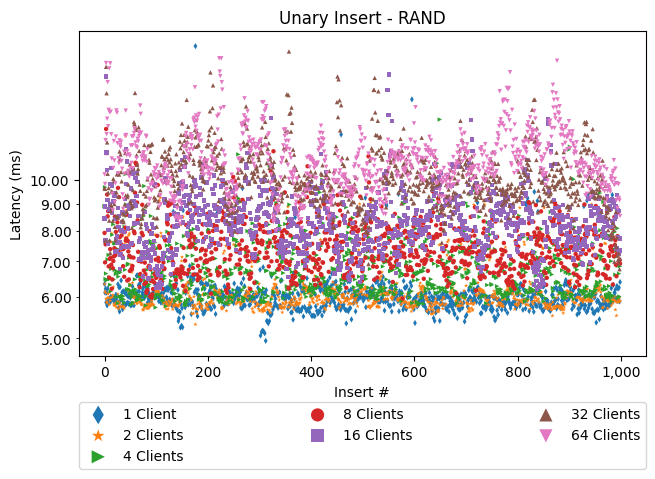

In [12]:
unaryPlots("INSERT_UNARY_RAND", "InfluxDB", targetThreads, client_ips, "Insert", logScale=True)

## Experiment – BATCH INSERT (SEQ)
**Perform experiments**

In [13]:
runWorkload("INSERT_BATCH_SEQ", targetThreads, server_local_ips[server_ips[0]], 9492, "InfluxDB", client_ips, 1000, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1760591828
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1760591775 | Delta: 53
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1760592012
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1760591959 | Delta: 53
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1760592201
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1760592148 | Delta: 53
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1760592461
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1760592348 | Delta: 113
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1760592355 | Delta: 106
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

**Visualization**

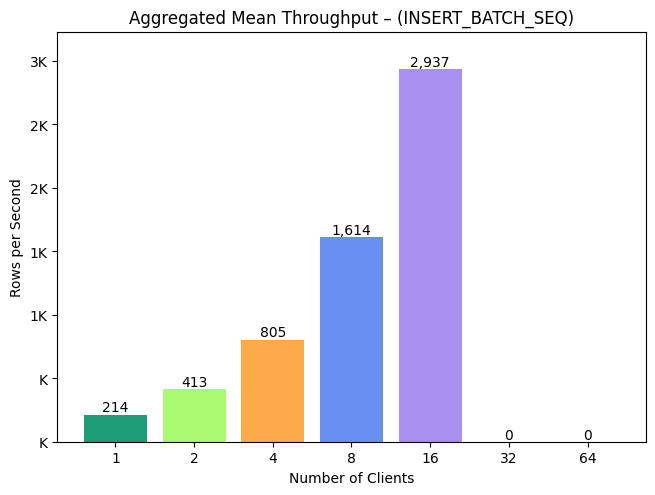

In [14]:
batchPlots("INSERT_BATCH_SEQ", "InfluxDB", targetThreads, client_ips)

## Experiment – BATCH INSERT (RAND)
**Perform experiments**

In [15]:
runWorkload("INSERT_BATCH_RAND", targetThreads, server_local_ips[server_ips[0]], 9492, "InfluxDB", client_ips, 1000, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1760594115
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1760594062 | Delta: 53
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1760594299
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1760594246 | Delta: 53
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1760594489
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1760594435 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1760594750
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1760594636 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1760594643 | Delta: 107
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

**Visualization**

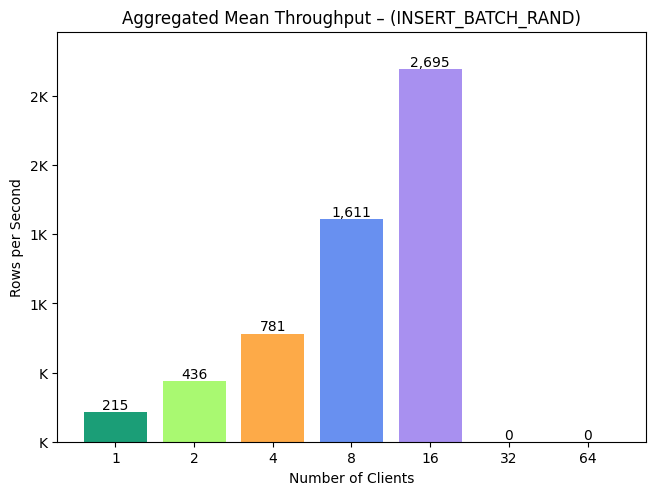

In [16]:
batchPlots("INSERT_BATCH_RAND", "InfluxDB", targetThreads, client_ips)

## Bootstrap Database

Reboot server to a fresh state to avoid becoming non-accessible from public network

In [17]:
rebootGroup(allGroup)

# Buffer of reboot (no more +1 min shutdown-schedule delay)
time.sleep(240)

for ip in (server_ips + client_ips):
    waitForSSH(ip, user=sshUser, timeout=1200)

<div class="alert alert-block alert-info">Note: This is required so that there's actual data for clients to query from</div>

In [18]:
serverGroup.put("../scripts/restoreDB.sh")

# Restore DB
serverGroup.run(f"bash restoreDB.sh MYSTIC@IIT InfluxDB BENCH_DB {SERVER_WORKING_DIR}", hide=True)

# Keep checking if job is done running in tmux window
checkTmuxJobIsDone(serverGroup);

## Experiment – UNARY QUERY (SEQ)

**Perform experiments**

In [19]:
runWorkload("QUERY_UNARY_SEQ", targetThreads, server_local_ips[server_ips[0]], 9492, "InfluxDB", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1760401025
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1760400971 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1760401207
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1760401153 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1760401397
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1760401343 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1760401655
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1760401542 | Delta: 113
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1760401548 | Delta: 107
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

**Visualization**

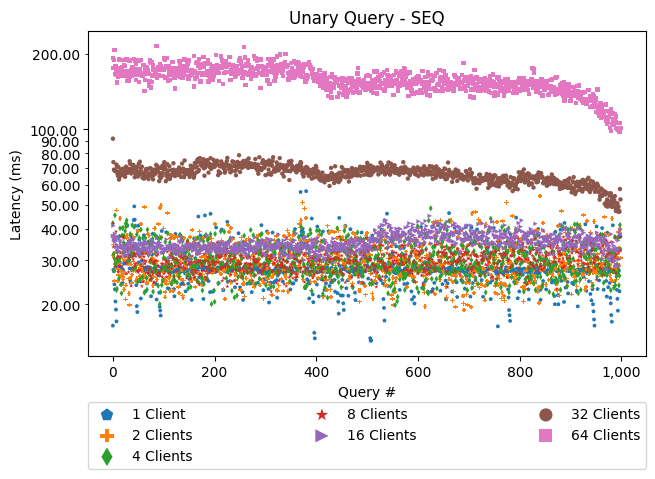

In [20]:
unaryPlots("QUERY_UNARY_SEQ", "InfluxDB", targetThreads, client_ips, "Query", logScale=True)

## Experiment – UNARY QUERY (RAND)

**Perform experiments**

In [21]:
runWorkload("QUERY_UNARY_RAND", targetThreads, server_local_ips[server_ips[0]], 9492, "InfluxDB", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1760403274
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1760403220 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1760403766
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1760403712 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1760404276
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1760404222 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1760404852
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1760404738 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1760404744 | Delta: 108
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

**Visualization**

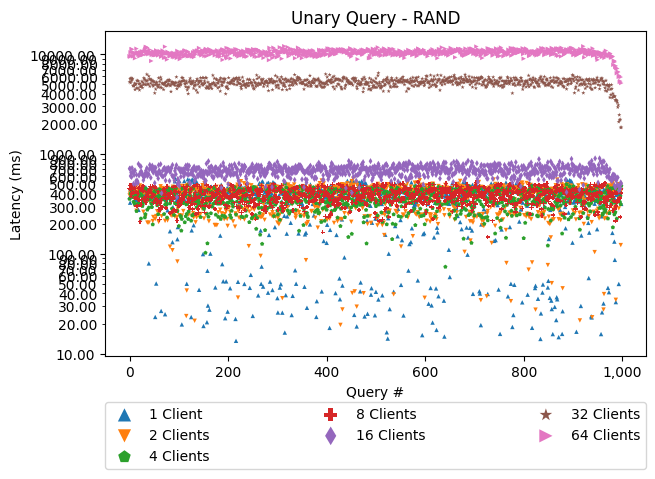

In [22]:
unaryPlots("QUERY_UNARY_RAND", "InfluxDB", targetThreads, client_ips, "Query", logScale=True)

## Experiment – BATCH QUERY (SEQ)

**Perform experiments**

In [23]:
runWorkload("QUERY_BATCH_SEQ", targetThreads, server_local_ips[server_ips[0]], 9492, "InfluxDB", client_ips, 100, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1760484587
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1760484533 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1760484774
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1760484720 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1760484963
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1760484909 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1760485227
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1760485114 | Delta: 113
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1760485120 | Delta: 107
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

**Visualization**

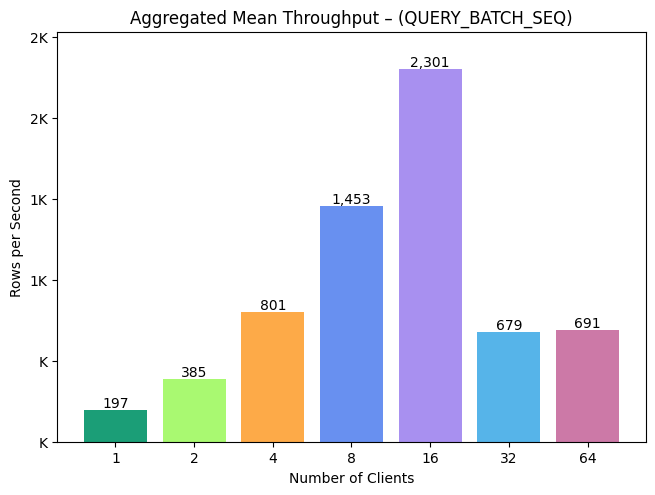

In [24]:
batchPlots("QUERY_BATCH_SEQ", "InfluxDB", targetThreads, client_ips, 100)

## Refresh Database

Reboot server to a fresh state to avoid becoming non-accessible from public network

In [25]:
rebootGroup(allGroup)

# Buffer of reboot (no more +1 min shutdown-schedule delay)
time.sleep(240)

for ip in (server_ips + client_ips):
    waitForSSH(ip, user=sshUser, timeout=1200)

## Experiment – MIN AGG QUERY

**Perform experiments**

In [26]:
runWorkload("AGG_MIN_QUERY", targetThreads, server_local_ips[server_ips[0]], 9492, "InfluxDB", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1763330326
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1763330273 | Delta: 53
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1763330513
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1763330459 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1763330702
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1763330648 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1763330965
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1763330851 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1763330858 | Delta: 107
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

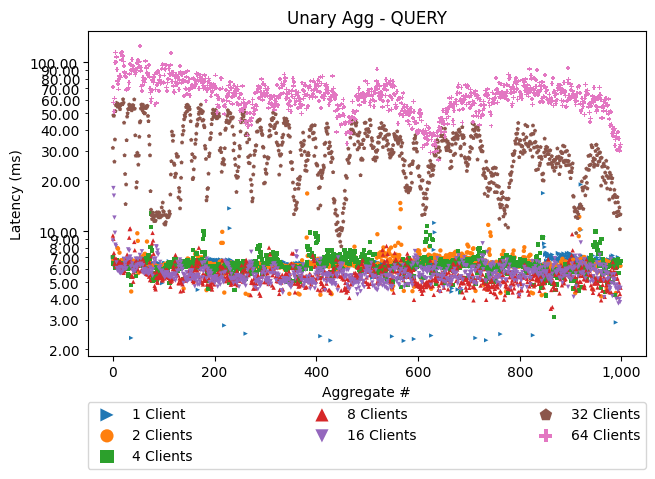

In [27]:
unaryPlots("AGG_MIN_QUERY", "InfluxDB", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – MAX AGG QUERY

**Perform experiments**

In [28]:
runWorkload("AGG_MAX_QUERY", targetThreads, server_local_ips[server_ips[0]], 9492, "InfluxDB", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1763332432
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1763332378 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1763332617
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1763332563 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1763332810
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1763332756 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1763333071
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1763332957 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1763332963 | Delta: 108
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

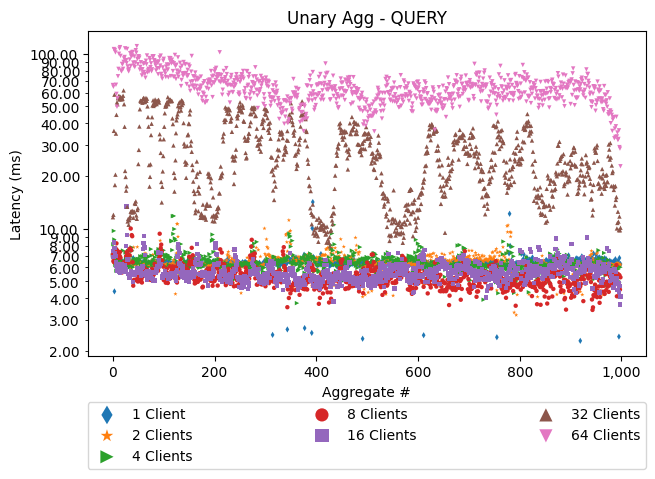

In [29]:
unaryPlots("AGG_MAX_QUERY", "InfluxDB", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – SUM AGG QUERY

**Perform experiments**

In [30]:
runWorkload("AGG_SUM_QUERY", targetThreads, server_local_ips[server_ips[0]], 9492, "InfluxDB", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1763334546
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1763334492 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1763334728
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1763334674 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1763334919
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1763334865 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1763335185
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1763335071 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1763335077 | Delta: 108
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

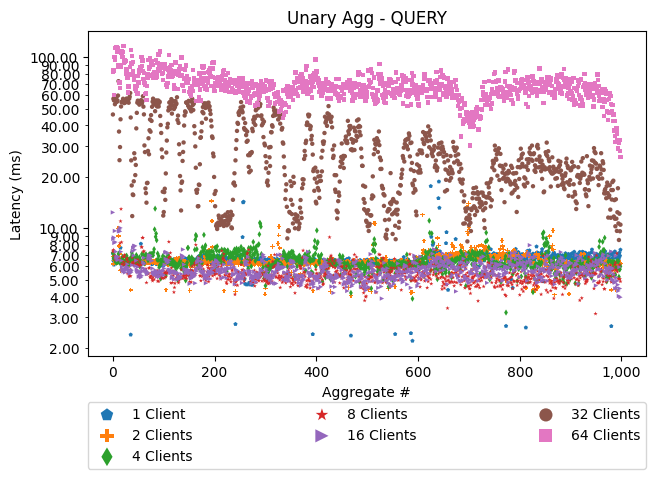

In [31]:
unaryPlots("AGG_SUM_QUERY", "InfluxDB", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – AVG AGG QUERY

**Perform experiments**

In [32]:
runWorkload("AGG_AVG_QUERY", targetThreads, server_local_ips[server_ips[0]], 9492, "InfluxDB", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1763336658
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1763336604 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1763336844
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1763336790 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1763337033
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1763336979 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1763337297
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1763337183 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1763337189 | Delta: 108
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

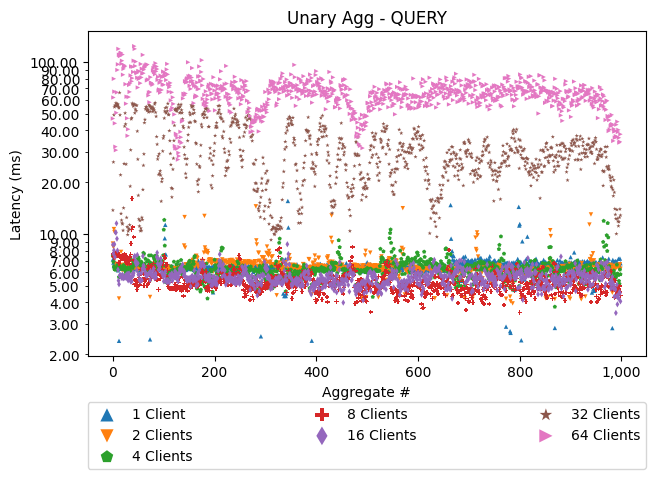

In [33]:
unaryPlots("AGG_AVG_QUERY", "InfluxDB", targetThreads, client_ips, "Aggregate", logScale=True)